# Coarse Fog Masking 實作與測試 (真實影片版)

這份 Notebook 實作了專案 Proposal 中定義的 **Coarse Fog Masking (粗略遮罩)**。利用局部對比度、HSV 飽和度以及影像梯度，透過聯集投票機制來找出初步的起霧像素。

**成員 A 的任務**：請將真實的起霧影片放入資料夾中，修改下方 Cell 的 `video_path`，並不斷微調 `thresh_var`, `thresh_sat`, `thresh_grad` 這三個參數，直到遮罩能完美捕捉到水氣且不誤判正常場景為止。

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 設定 matplotlib 顯示大小
plt.rcParams['figure.figsize'] = [18, 12]

part 1: coarse fog mask

### 核心函式定義

In [2]:
def get_coarse_fog_mask(image_bgr, 
                        patch_size=15, 
                        thresh_var=0.015, 
                        thresh_sat=0.3, 
                        thresh_grad=0.15,
                        thresh_val=0.5):  # 🌟 新增明度閾值參數
    # 1. 影像預處理
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0
    
    # 特徵一：對比度特徵 (Contrast)
    mean_of_sq = cv2.blur(gray**2, (patch_size, patch_size))
    sq_of_mean = cv2.blur(gray, (patch_size, patch_size))**2
    variance = np.clip(mean_of_sq - sq_of_mean, 0, None)
    mask_contrast = variance < thresh_var
    
    # 特徵二 & 新增的特徵四：飽和度 (Saturation) 與 明度 (Value)
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    sat = hsv[:, :, 1].astype(np.float32) / 255.0
    mask_sat = sat < thresh_sat
    
    val = hsv[:, :, 2].astype(np.float32) / 255.0
    mask_bright = val > thresh_val  # 🌟 新增：亮度必須大於閾值
    
    # 特徵三：梯度特徵 (Gradient)
    sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    grad_mag = np.sqrt(sobelx**2 + sobely**2)
    mask_grad = grad_mag < thresh_grad
    
    # 決策：投票機制 (符合兩項以上)
    votes = mask_contrast.astype(np.uint8) + \
            mask_sat.astype(np.uint8) + \
            mask_grad.astype(np.uint8)
            
    # 🌟 關鍵修改：得票數 >= 2，【且】亮度必須夠高
    coarse_mask = ((votes >= 2) & mask_bright).astype(np.uint8) * 255
    
    # 形態學操作去噪
    kernel = np.ones((5, 5), np.uint8)
    coarse_mask = cv2.morphologyEx(coarse_mask, cv2.MORPH_OPEN, kernel)
    coarse_mask = cv2.morphologyEx(coarse_mask, cv2.MORPH_CLOSE, kernel)
    
    # 🌟 更新 debug 字典，加入 brightness
    debug_masks = {
        'contrast': (mask_contrast.astype(np.uint8) * 255),
        'saturation': (mask_sat.astype(np.uint8) * 255),
        'gradient': (mask_grad.astype(np.uint8) * 255),
        'brightness': (mask_bright.astype(np.uint8) * 255), # <--- 這裡加進去
        'votes_map': (votes * 85).astype(np.uint8)
    }
    
    return coarse_mask, debug_masks

### 讀取真實影片與視覺化
請將 `video_path` 替換為你們手邊的影片路徑。你可以透過改變 `frame_id` 來隨機抽查影片中的不同時間點，確保參數在整支影片中都具備泛化能力。

✅ 成功讀取第 100 幀，影像大小: (854, 480, 3)


C:\Users\USER\AppData\Local\Temp\ipykernel_3896\3520616412.py:73: UserWarning: Glyph 127775 (\N{GLOWING STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


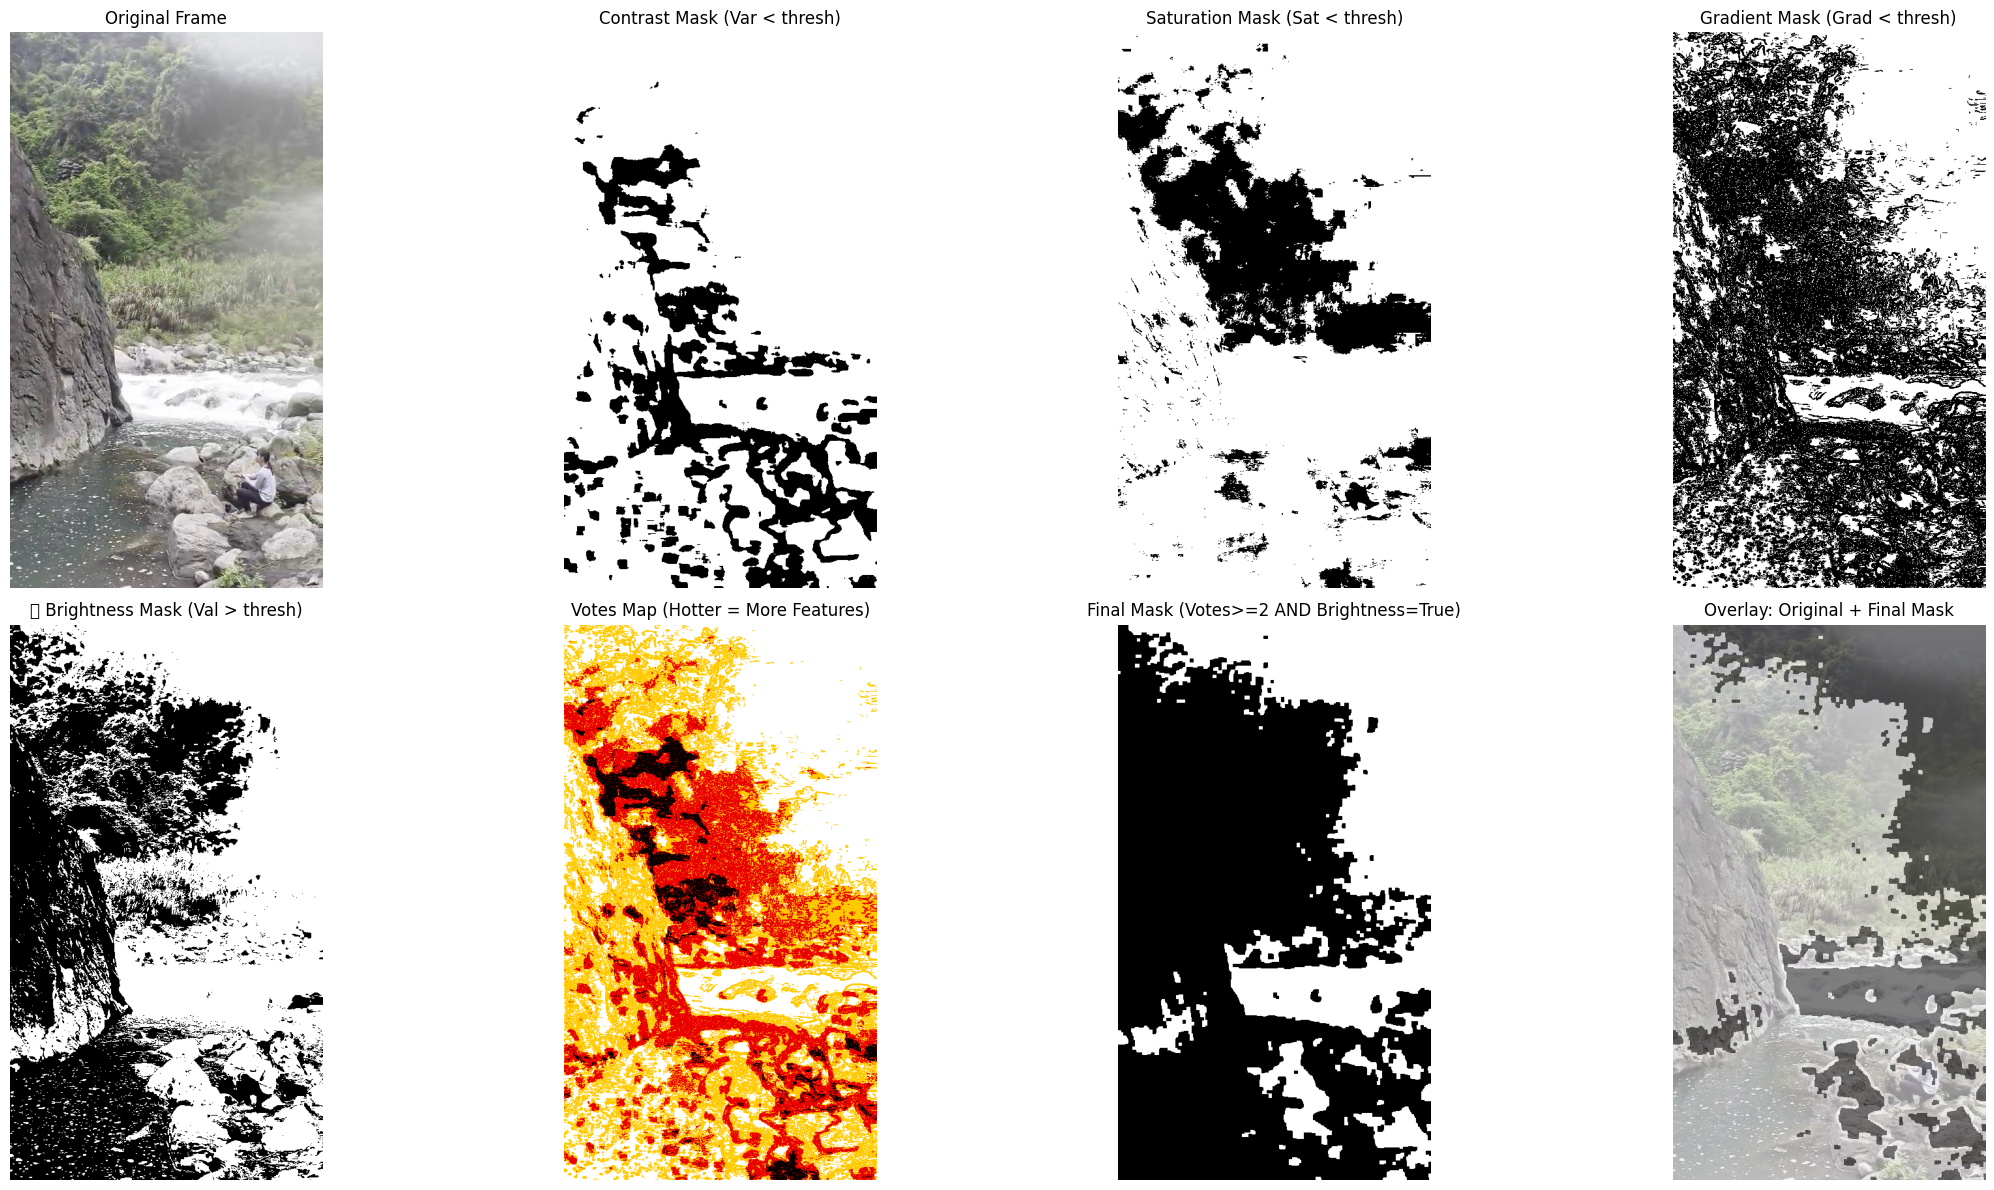

In [9]:
# ==========================================
# 1. 設定影片路徑與抽樣幀數
# ==========================================
video_path = './data/foggy_vid/1.mp4'  # <--- 在這裡換成你們的測試影片名稱
frame_id = 100                     # <--- 試著改成不同的數字 (例如 0, 50, 300) 來看不同時間點的霧氣

cap = cv2.VideoCapture(video_path)
cap.set(cv2.CAP_PROP_POS_FRAMES, frame_id)
ret, frame = cap.read()

if not ret:
    print(f"⚠️ 無法讀取影片 '{video_path}' 或是 frame_id 超出範圍。請確認檔名是否正確且放在同一資料夾！")
    # 為了防呆，產生一張黑色測試圖避免報錯
    frame = np.zeros((720, 1280, 3), dtype=np.uint8)
else:
    print(f"✅ 成功讀取第 {frame_id} 幀，影像大小: {frame.shape}")
    # 如果手機拍的影片是 4K (3840x2160) 等高解析度，建議先縮小，加快演算法驗證速度
    # frame = cv2.resize(frame, (1280, 720))

# 執行函式 (記得補上 thresh_val 參數)
final_mask, debug = get_coarse_fog_mask(
    frame, 
    patch_size=15, 
    thresh_var=0.015,    # 放寬一點對比度
    thresh_sat=0.1,     # 放寬一點飽和度
    thresh_grad=0.15,    # 放寬一點梯度
    thresh_val=0.55     # 新增：亮度要大於 0.55 才算霧 (濾掉石頭)
)

frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

# ==========================================
# 繪製結果 (改成 2x4 的網格，共 8 格)
# ==========================================
fig, axes = plt.subplots(2, 4, figsize=(24, 12))

# --- 第一排：原圖與三大原始特徵 ---
axes[0, 0].imshow(frame_rgb)
axes[0, 0].set_title('Original Frame')
axes[0, 0].axis('off')

axes[0, 1].imshow(debug['contrast'], cmap='gray')
axes[0, 1].set_title('Contrast Mask (Var < thresh)')
axes[0, 1].axis('off')

axes[0, 2].imshow(debug['saturation'], cmap='gray')
axes[0, 2].set_title('Saturation Mask (Sat < thresh)')
axes[0, 2].axis('off')

axes[0, 3].imshow(debug['gradient'], cmap='gray')
axes[0, 3].set_title('Gradient Mask (Grad < thresh)')
axes[0, 3].axis('off')

# --- 第二排：新增的亮度特徵、投票結果與最終輸出 ---
axes[1, 0].imshow(debug['brightness'], cmap='gray')
axes[1, 0].set_title('🌟 Brightness Mask (Val > thresh)')
axes[1, 0].axis('off')

axes[1, 1].imshow(debug['votes_map'], cmap='hot')
axes[1, 1].set_title('Votes Map (Hotter = More Features)')
axes[1, 1].axis('off')

axes[1, 2].imshow(final_mask, cmap='gray')
axes[1, 2].set_title('Final Mask (Votes>=2 AND Brightness=True)')
axes[1, 2].axis('off')

# show the original image with the final mask overlaid (for better visualization)
axes[1, 3].imshow(frame_rgb)
axes[1, 3].imshow(final_mask, cmap='Greys', alpha=0.5)  # 半透明疊加
axes[1, 3].set_title('Overlay: Original + Final Mask')
axes[1, 3].axis('off')

plt.tight_layout()
plt.show()